In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os, os.path
import numpy as np
import warnings
import re
from sklearn.svm import SVC
from scipy.interpolate import interp1d
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report, r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.signal import savgol_filter
from sklearn.svm import SVR
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout, Bidirectional
from sklearn.isotonic import IsotonicRegression
from pathlib import Path

warnings.filterwarnings("ignore")


BASE_DIR = Path("OSA_measurements")

In [8]:

def mWtoDBm(val):
    return 10*np.log10(val)

def load_wad_file(filepath):
    try:
        with open(filepath, 'r') as f:
            lines = f.readlines()
        data_start_idx = None
        for idx, line in enumerate(lines):
            if line.strip() == "Data:":
                data_start_idx = idx + 2  
                break
        
        if data_start_idx is None:
            print(f"Warning: Could not find 'Data:' section in {filepath}")
            return None
        data_lines = lines[data_start_idx:]
        frequencies = []
        wavelengths = []
        powers = []
        
        for line in data_lines:
            line = line.strip()
            if not line:  
                continue
            try:
                parts = line.split()
                if len(parts) >= 3:
                    frequencies.append(float(parts[0]))
                    wavelengths.append(float(parts[1]))
                    powers.append(float(parts[2]))
            except ValueError:
                continue
        
        # Create dataframe
        df = pd.DataFrame({
            'Frequency [THz]': frequencies,
            'Wavelength [nm]': wavelengths,
            'Absolute Power [mW]': powers
        })

        return df
    
    except Exception as e:
        print(f"Error loading {filepath}: {e}")
        return None
    
def fill_nan_with_neighbors(df):
    df_filled = df.copy()
    feature_cols = [col for col in df.columns if col not in ['day', 'depth_cm', 'label']]
    for idx in range(len(df_filled)):
        if df_filled.iloc[idx][feature_cols].isna().any():
            for col in feature_cols:
                if pd.isna(df_filled.iloc[idx][col]):
                    before_val = df_filled.iloc[idx-1][col] if idx > 0 else None
                    after_val = df_filled.iloc[idx+1][col] if idx < len(df_filled)-1 else None
                    
                    if before_val is not None and after_val is not None and not pd.isna(before_val) and not pd.isna(after_val):
                        df_filled.loc[df_filled.index[idx], col] = (before_val + after_val) / 2
                    elif before_val is not None and not pd.isna(before_val):
                        df_filled.loc[df_filled.index[idx], col] = before_val
                    elif after_val is not None and not pd.isna(after_val):
                        df_filled.loc[df_filled.index[idx], col] = after_val
    return df_filled


def extract_wavelengths_at_power(sensor_data, fiber_id, expected_wavelengths, target_power=-55.0, tolerance=1.0, smoothing_window=1, subtract_day0=False):
    fiber_base = fiber_id.split('_')[0]
    
    if fiber_base not in expected_wavelengths:
        raise ValueError(f"Fiber {fiber_base} not found in expected_wavelengths")
    
    expected_wl = expected_wavelengths[fiber_base]

    if fiber_id.endswith('_V6_2'):
            position_mapping = peak_to_position_V6.get(fiber_base, {})
    if fiber_id.endswith('_V6'):
        position_mapping = peak_to_position_V6.get(fiber_base, {})
    elif fiber_id.endswith('_V5'):
        position_mapping = peak_to_position_V5.get(fiber_base, {})
    elif fiber_id.endswith('_V4'):
        position_mapping = peak_to_position_V4.get(fiber_base, {})
    elif fiber_id.endswith('_V3'):
        position_mapping = peak_to_position_V3.get(fiber_base, {})
    elif fiber_id.endswith('_V2'):
        position_mapping = peak_to_position_V2.get(fiber_base, {})
    else:
        position_mapping = peak_to_position_V3.get(fiber_base, {})
    
    results = []
    wavelengths = sensor_data['Wavelength [nm]'].values
    
    for col in sensor_data.columns:
        if col == 'Wavelength [nm]':
            continue
        
        match = re.match(r'D(\d+)', col)
        day_number = int(match.group(1)) if match else None
        
        power_values = sensor_data[col].values
        
        if smoothing_window > 1:
            window = np.ones(smoothing_window) / smoothing_window
            power_values = np.convolve(power_values, window, mode='same')

        row_data = {'day': day_number}
        
        for peak_idx, expected_wl_value in enumerate(expected_wl):
            closest_idx = np.argmin(np.abs(wavelengths - expected_wl_value))
            search_range = 200  
            start_idx = max(0, closest_idx - search_range)
            end_idx = min(len(wavelengths), closest_idx + search_range)
            
            search_wl = wavelengths[start_idx:end_idx]
            search_power = power_values[start_idx:end_idx]
            
            peak_center_idx = np.argmax(search_power)
            peak_center_wl = search_wl[peak_center_idx]
            peak_center_power = search_power[peak_center_idx]
            
            trailing_edge_mask = search_wl >= peak_center_wl
            trailing_wl = search_wl[trailing_edge_mask]
            trailing_power = search_power[trailing_edge_mask]
            
            if len(trailing_wl) == 0:
                position = position_mapping.get(peak_idx, f'peak_{peak_idx}')
                row_data[position] = np.nan
                continue
            
            power_diffs = np.abs(trailing_power - target_power)
            close_indices = np.where(power_diffs <= tolerance)[0]
            
            if len(close_indices) > 0:
                first_crossing_idx = close_indices[0]
                wavelength_at_target = trailing_wl[first_crossing_idx]
                position = position_mapping.get(peak_idx, f'peak_{peak_idx}')
                row_data[position] = wavelength_at_target
            else:
                try:
                    if len(trailing_wl) > 2 and target_power < peak_center_power:
                        f_interp = interp1d(trailing_power, trailing_wl, kind='linear', 
                                          fill_value='extrapolate', bounds_error=False)
                        wavelength_at_target = f_interp(target_power)
                        
                        if wavelength_at_target >= peak_center_wl:
                            position = position_mapping.get(peak_idx, f'peak_{peak_idx}')
                            row_data[position] = wavelength_at_target
                        else:
                            position = position_mapping.get(peak_idx, f'peak_{peak_idx}')
                            row_data[position] = np.nan
                    else:
                        position = position_mapping.get(peak_idx, f'peak_{peak_idx}')
                        row_data[position] = np.nan
                except:
                    position = position_mapping.get(peak_idx, f'peak_{peak_idx}')
                    row_data[position] = np.nan
        
        results.append(row_data)
    
    result_df = pd.DataFrame(results)
    result_df = result_df.sort_values('day').reset_index(drop=True)
    if not subtract_day0:
        desired_cols = ['day', 'left', 'center', 'right', 'reference']
        existing_cols = [col for col in desired_cols if col in result_df.columns]
        return result_df[existing_cols]
    if 0 in result_df['day'].values:
        day0_idx = result_df[result_df['day'] == 0].index[0]
    else:
        day0_idx = 0  
    
    wavelength_cols = [col for col in result_df.columns if col != 'day']
    day0_wavelengths = result_df.loc[day0_idx, wavelength_cols].copy()
    
    for col in wavelength_cols:
        result_df[col] = (result_df[col] - day0_wavelengths[col])
    
    desired_cols = ['day', 'left', 'center', 'right', 'reference']
    existing_cols = [col for col in desired_cols if col in result_df.columns]
    return result_df[existing_cols]


def combine_fiber_pair(shallow_df, deep_df):
    combined = pd.DataFrame({'day': shallow_df['day']})

    if 'left' in shallow_df.columns:
        combined['shallow_left'] = shallow_df['left']
    if 'center' in shallow_df.columns:
        combined['shallow_center'] = shallow_df['center']
    if 'right' in shallow_df.columns:
        combined['shallow_right'] = shallow_df['right']

    if 'left' in deep_df.columns:
        combined['deep_left'] = deep_df['left']
    if 'center' in deep_df.columns:
        combined['deep_center'] = deep_df['center']
    if 'right' in deep_df.columns:
        combined['deep_right'] = deep_df['right']

    if 'reference' in shallow_df.columns:
        combined['reference'] = shallow_df['reference']
    
    return combined


def plot_all_lopocv_results(
    plant_names_list, plant_data_dict, predictions_dict, metric="mae"):

  valid_plants = [
      name for name in plant_names_list if name in predictions_dict
  ]
  num_plants = len(valid_plants)

  if num_plants == 0:
    print("No predictions found to plot!")
    return

  # Calculate performance metrics for each plant
  plant_metrics = []
  for name in valid_plants:
    y_actual = plant_data_dict[name]["y"]
    y_predicted = predictions_dict[name]

    mae_depth = np.mean(np.abs(y_actual[:, 0] - y_predicted[:, 0]))
    mae_width = np.mean(np.abs(y_actual[:, 1] - y_predicted[:, 1]))
    avg_mae = (mae_depth + mae_width) / 2.0

    # Optional R2 metric logic
    ss_tot_d = np.sum((y_actual[:, 0] - np.mean(y_actual[:, 0])) ** 2)
    r2_depth = (
        1 - (np.sum((y_actual[:, 0] - y_predicted[:, 0]) ** 2) / ss_tot_d)
        if ss_tot_d != 0
        else 0
    )

    ss_tot_w = np.sum((y_actual[:, 1] - np.mean(y_actual[:, 1])) ** 2)
    r2_width = (
        1 - (np.sum((y_actual[:, 1] - y_predicted[:, 1]) ** 2) / ss_tot_w)
        if ss_tot_w != 0
        else 0
    )

    avg_r2 = (r2_depth + r2_width) / 2.0

    plant_metrics.append({
        "name": name,
        "avg_mae": avg_mae,
        "mae_depth": mae_depth,
        "mae_width": mae_width,
        "avg_r2": avg_r2,
        "r2_depth": r2_depth,
        "r2_width": r2_width,
    })

  # Sort plants by performance
  if metric.lower() == "r2":
    sorted_plants = sorted(
        plant_metrics, key=lambda x: x["avg_r2"], reverse=True
    )
  else:
    sorted_plants = sorted(plant_metrics, key=lambda x: x["avg_mae"])

  global_max_days = max(
      len(plant_data_dict[name]["y"]) - 1 for name in valid_plants
  )

  global_max_depth = max(
      max(
          np.max(plant_data_dict[name]["y"][:, 0]),
          np.max(predictions_dict[name][:, 0]),
      )
      for name in valid_plants
  )

  global_max_width = max(
      max(
          np.max(plant_data_dict[name]["y"][:, 1]),
          np.max(predictions_dict[name][:, 1]),
      )
      for name in valid_plants
  )

  fig, axes = plt.subplots(
      nrows=num_plants, ncols=2, figsize=(16, 4 * num_plants)
  )

  if num_plants == 1:
    axes = np.array([axes])

  for i, item in enumerate(sorted_plants):
    name = item["name"]
    y_actual = plant_data_dict[name]["y"]
    y_predicted = predictions_dict[name]
    days = np.arange(len(y_actual))

    rank_str = f"Rank #{i+1}"

    ax_depth = axes[i, 0]
    ax_depth.plot(days, y_actual[:, 0], "g--", label="Teacher Target (Depth)")
    ax_depth.plot(
        days, y_predicted[:, 0], "g-", linewidth=2.5, label="Predicted Depth"
    )
    ax_depth.set_title(
        f"[{rank_str}] {name} - Depth Prediction (MAE: {item['mae_depth']:.2f}"
        " cm)"
    )
    ax_depth.set_ylabel("Depth (cm)")
    ax_depth.set_xlabel("Days Elapsed")
    ax_depth.set_xlim(0, global_max_days)
    ax_depth.set_ylim(0, global_max_depth * 1.05) 
    ax_depth.grid(axis="both", linestyle="--", alpha=0.6)
    ax_depth.legend(loc="upper left")

    ax_width = axes[i, 1]
    ax_width.plot(days, y_actual[:, 1], "b--", label="Teacher Target (Width)")
    ax_width.plot(
        days, y_predicted[:, 1], "b-", linewidth=2.5, label="Predicted Width"
    )
    ax_width.set_title(
        f"[{rank_str}] {name} - Width Prediction (MAE: {item['mae_width']:.2f}"
        " cm)"
    )
    ax_width.set_ylabel("Width (cm)")
    ax_width.set_xlabel("Days Elapsed")
    ax_width.set_xlim(0, global_max_days)
    ax_width.set_ylim(0, global_max_width * 1.05)  
    ax_width.grid(axis="both", linestyle="--", alpha=0.6)
    ax_width.legend(loc="upper left")

  plt.tight_layout()
  plt.show()

def generate_augmented_features(raw_sensors, scale=1.0, noise_std=0.0, swap_lr=False, left_scale=1.0, right_scale=1.0):
    aug_sensors = raw_sensors.copy()

    if swap_lr:
        aug_sensors[:, [0, 2]] = aug_sensors[:, [2, 0]]
        aug_sensors[:, [3, 5]] = aug_sensors[:, [5, 3]]
        
    aug_sensors[:, [0, 3]] *= left_scale
    aug_sensors[:, [2, 5]] *= right_scale
    
    aug_sensors = aug_sensors * scale
    if noise_std > 0:
        noise = np.random.normal(0, noise_std, aug_sensors.shape)
        aug_sensors += noise
        
    df_calc = pd.DataFrame(aug_sensors, columns=['sl', 'sc', 'sr', 'dl', 'dc', 'dr'])
    
    df_roll3 = df_calc.rolling(window=3, min_periods=1).mean().values
    df_roll7 = df_calc.rolling(window=7, min_periods=1).mean().values
    df_std5 = df_calc.rolling(window=5, min_periods=1).std().fillna(0).values
    df_del = df_calc.diff(1).fillna(0).values
    df_vol = df_calc.rolling(window=3, min_periods=1).median().diff().abs().fillna(0).values

    corr_center = df_calc['sc'].rolling(window=5, min_periods=2).corr(df_calc['dc']).fillna(0).values
    corr_left = df_calc['sl'].rolling(window=5, min_periods=2).corr(df_calc['dl']).fillna(0).values
    corr_right = df_calc['sr'].rolling(window=5, min_periods=2).corr(df_calc['dr']).fillna(0).values
    corr_shallow_lr = df_calc['sl'].rolling(window=5, min_periods=2).corr(df_calc['sr']).fillna(0).values
    corr_deep_lr = df_calc['dl'].rolling(window=5, min_periods=2).corr(df_calc['dr']).fillna(0).values

    abs_sensors = np.abs(aug_sensors)
    
    left_sum = (abs_sensors[:,0] + abs_sensors[:,3]) - abs_sensors[:,1]
    right_sum = (abs_sensors[:,2] + abs_sensors[:,5]) - abs_sensors[:,4]
    side_ratio = left_sum / (right_sum + 1e-5)
    
    shallow_sum = np.sum(abs_sensors[:, :3], axis=1)
    deep_sum = np.sum(abs_sensors[:, 3:], axis=1)
    spatial_ratio = shallow_sum / (deep_sum + 1e-5) 
    
    daily_work = np.sum(abs_sensors, axis=1)
    running_cumulative_work = np.cumsum(daily_work)

    max_velocity = np.maximum.accumulate(np.abs(df_del), axis=0)

    auc_strain = np.zeros_like(abs_sensors)
    if len(abs_sensors) > 1:
        auc_strain[1:] = np.cumsum((abs_sensors[1:] + abs_sensors[:-1]) / 2.0, axis=0)

    lr_diff = (abs_sensors[:,0] + abs_sensors[:,3]) - (abs_sensors[:,2] + abs_sensors[:,5])
    asym_variance = pd.Series(lr_diff).rolling(window=7, min_periods=2).var().fillna(0).values

    outer_strain = abs_sensors[:, 0] + abs_sensors[:, 2] + abs_sensors[:, 3] + abs_sensors[:, 5]
    inner_strain = abs_sensors[:, 1] + abs_sensors[:, 4]
    outer_inner_ratio = outer_strain / (inner_strain + 1e-5)
    
    spatial_divergence = np.abs((abs_sensors[:, 0] + abs_sensors[:, 3]) - (abs_sensors[:, 2] + abs_sensors[:, 5]))
    cum_spatial_divergence = np.zeros_like(spatial_divergence)
    if len(spatial_divergence) > 1:
        cum_spatial_divergence[1:] = np.cumsum((spatial_divergence[1:] + spatial_divergence[:-1]) / 2.0, axis=0)

    return np.column_stack((
        aug_sensors, df_roll3, df_roll7, df_std5, 
        spatial_ratio, running_cumulative_work, daily_work,
        side_ratio, df_del, df_vol,
        corr_center, corr_left, corr_right, corr_shallow_lr, corr_deep_lr,
        max_velocity, auc_strain, asym_variance,
        outer_inner_ratio, cum_spatial_divergence
    ))

def extract_number(text: str) -> int:
    match = re.search(r'\d+', text)
    return int(match.group()) if match else 0

def load_version_metadata(version: str, config: dict, root: Path = BASE_DIR) -> dict[str, pd.DataFrame]:
    version_path = root / version

    if not config['enabled']:
        print(f"{version} data excluded (enabled = False)")
        return {}
    if not version_path.exists():
        print(f"{version} data path not found: {version_path}")
        return {}

    print(f"Loading {version} data...")
    fiber_map = {f"F{i}": f"F{i}_{version}" for i in config['fibers']}
    records = {fiber_id: [] for fiber_id in fiber_map.values()}

    if config['layout'] == 'day_first':
        day_folders = sorted(
            [d for d in version_path.iterdir() if d.is_dir()],
            key=lambda d: extract_number(d.name)
        )
        for day_dir in day_folders:
            for file_path in day_dir.glob("*.wad"):
                if file_path.stem in fiber_map:
                    fiber_id = fiber_map[file_path.stem]
                    records[fiber_id].append({
                        'filename': f"{day_dir.name}.wad",
                        'folder': fiber_id,
                        'filepath': str(file_path),
                        'version': version,
                        'sensor_location': fiber_id,
                    })

    elif config['layout'] == 'fiber_first':
        for fiber_base, fiber_id in fiber_map.items():
            fiber_dir = version_path / fiber_base
            if not fiber_dir.exists():
                continue
            wad_files = sorted(
                [f for f in fiber_dir.glob("*.wad") if not f.name.startswith("D-")],
                key=lambda f: extract_number(f.name)
            )
            for file_path in wad_files:
                records[fiber_id].append({
                    'filename': file_path.name,
                    'folder': fiber_id,
                    'filepath': str(file_path),
                    'version': version,
                    'sensor_location': fiber_id,
                })

    result = {fid: pd.DataFrame(rows) for fid, rows in records.items() if rows}
    print(f"  Loaded {len(result)} {version} fibers")
    return result

def apply_pca_with_reference(df, active_cols, reference_col, n_components_to_drop=1):

    all_cols = active_cols + [reference_col]
    X = df[all_cols].values

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    pca = PCA(n_components=len(all_cols))
    X_pca = pca.fit_transform(X_scaled)

    for i in range(n_components_to_drop):
        X_pca[:, i] = 0

    X_reconstructed_scaled = pca.inverse_transform(X_pca)

    X_reconstructed = scaler.inverse_transform(X_reconstructed_scaled)
    
    df_filtered = df.copy()
   
    for idx, col in enumerate(all_cols):
        if col in active_cols:
            df_filtered[col] = X_reconstructed[:, idx]
            
    return df_filtered, pca.explained_variance_ratio_


def calculate_sensor_rate(df, sensor_col='shallow_center', reference_days=30.0, method='linear'):
    days = df['day'].values if 'day' in df.columns else df.index.values
    if len(days) == 0:
        days = np.arange(len(df))
        
    sensor_vals = df[sensor_col].values
    
    # Filter sensor data within the active window [0, reference_days]
    mask = (days >= 0) & (days <= reference_days)
    window_days = days[mask]
    window_vals = sensor_vals[mask]
    
    if len(window_days) < 2:
        return 0.0
    
    if method == 'linear':
        rate, _ = np.polyfit(window_days, window_vals, 1)
    elif method == 'max_gradient':
        gradients = np.gradient(window_vals, window_days)
        max_idx = np.argmax(np.abs(gradients))
        rate = gradients[max_idx]
    else:
        rate = (window_vals[-1] - window_vals[0]) / (window_days[-1] - window_days[0])
        
    return rate

def generate_pseudo_labels(timeline, final_size, rate_shift_score=0.0, base_k=0.15, reference_days=30.0):

    base_t0 = reference_days / 2.0 
    t0 = base_t0 - (rate_shift_score * (reference_days * 0.25)) 
    
    curve = final_size / (1 + np.exp(-base_k * (timeline - t0)))
    curve = curve - curve[0]
    curve = curve * (final_size / curve[-1])
    
    return curve

def extract(sensor_key: str, expected_wl):
    return extract_wavelengths_at_power(
        sensor_restructured[sensor_key],
        sensor_key,
        expected_wl,
        target_power=pow,
        smoothing_window=win
    )

In [9]:
reference_wavelengths = {  
    'F1_V3': 1553.3,  
    'F3_V3': 1550,
    'F5_V3': 1552.5,
    'F7_V3': 1547.5,
    'F9_V3': 1552.5,
    'F11_V3': 1545,
    'F1_V2': 1547.5,  
    'F3_V2': 1547.5,  
    'F5_V2': 1550,    
    'F7_V2': 1545,    
    'F9_V2': 1545, 
    'F1_V4': 1553.3,  
    'F3_V4': 1550,
    'F5_V4': 1553.3,
    'F7_V4': 1545,
    'F9_V4': 1550,
    'F11_V4': 1552.5,
    'F1_V5': 1552.5,  
    'F3_V5': 1547.5,
    'F5_V5': 1553.3,
    'F7_V5': 1545,
    'F9_V5': 1545,
    'F11_V5': 1552,
    'F1_V6': 1552.5,  
    'F3_V6': 1547.5,
    'F5_V6': 1553.3,
    'F7_V6': 1545,
    'F9_V6': 1545,
    'F11_V6': 1552,
}

expected_wavelengths_V6 = {
    'F1': [1552.5, 1550, 1547.5, 1553.3],      
    'F2': [1552.5, 1550, 1547.5],          
    'F3': [1552.5, 1547.5,1550,1545,],     
    'F4': [1552.5, 1550, 1545],            
    'F5': [1550,1553.3,1545,1552.5,],        
    'F6': [1553.3, 1552.5, 1550],          
    'F7': [1552.5, 1547.5, 1545,1550,],    
    'F8': [1550, 1545, 1552.5],
    'F9': [ 1545, 1552.5, 1550,1547.5,],   
    'F10': [1552.5,1550,  1545],     
    'F11': [1550, 1547.5,1553.3, 1552.5],  
    'F12': [1552.5, 1547.5, 1550]            
}


expected_wavelengths_V5 = {
    'F1': [1552.5, 1550, 1545, 1553.3],       
    'F2': [1552.5, 1550, 1547.5],          
    'F3': [1552.5, 1547.5,1550,1545,],     
    'F4': [1552.5, 1550, 1545],            
    'F5': [1550,1553.3,1545,1552.5,],        
    'F6': [1553.3, 1552.5, 1550],          
    'F7': [1552.5, 1547.5, 1545,1550,],    
    'F8': [1550, 1545, 1552.5],
    'F9': [ 1545, 1552.5, 1550,1547.5,],   
    'F10': [1552.5,1550,  1545],     
    'F11': [1550, 1547.5,1553.3, 1552.5],  
    'F12': [1552.5, 1547.5, 1550]            
}

expected_wavelengths_V4 = {
    'F1': [ 1545, 1550, 1552.5,1553.3],    
    'F2': [1552.5, 1550, 1547.5],          
    'F3': [1552.5, 1547.5, 1550, 1545],    
    'F4': [1552.5, 1550, 1545],            
    'F5': [1552.5,1553.3,1545,1550],    
    'F6': [1553.3, 1552.5, 1550],         
    'F7': [1550, 1547.5, 1545,1552.5,],
    'F8': [1550, 1545,1552.5],         
    'F9': [1550, 1547.5,1552.5, 1545 ],    
    'F10': [1552.5, 1550, 1545],           
    'F11': [1553.3, 1547.5,1550, 1552.5],  
    'F12': [1552.5, 1547.5, 1550]          
}

expected_wavelengths_V3 = {
    'F1': [1545,  1550,1552.5,1553.3],       
    'F2': [1552.5, 1550, 1547.5],         
    'F3': [1552.5, 1547.5, 1550, 1545],      
    'F4': [1552.5, 1550, 1545],          
    'F5': [1553.3, 1550, 1552.5, 1545],        
    'F6': [1553.3, 1552.5, 1550],            
    'F7': [1552.5, 1547.5,1550, 1545],     
    'F8': [1550,1545, 1552.5 ],               
    'F9': [1545,1547.5,1552.5 ,  1550],     
    'F10': [1552.5, 1550, 1545],             
    'F11': [ 1550, 1547.5, 1545,1553.3],        
    'F12': [1552.5, 1547.5 ,1550]            
}

expected_wavelengths_V2 = { 
    'F1': [1553.3, 1552.5, 1550, 1547.5],    
    'F2': [1552.5, 1550, 1547.5],            
    'F3': [1552.5, 1550, 1547.5, 1545],      
    'F4': [1552.5, 1550, 1545],              
    'F5': [1553.3,  1545, 1550,1552.5],      
    'F6': [1553.3, 1545,1552.5 ],            
    'F7': [ 1547.5, 1550,1552.5, 1545],      
    'F8': [1552.5, 1550, 1545],              
    'F9': [ 1550,1552.5, 1547.5, 1545], 
    'F10': [1552.5, 1550, 1545]              
}

peak_to_position_V6 = {
    'F1': {3: 'left', 2: 'center', 1: 'right', 0: 'reference'},
    'F2': {0: 'left', 1: 'center', 2: 'right'},
    'F3': {0: 'left', 2: 'center', 3: 'right', 1: 'reference'},
    'F4': {0: 'left', 1: 'center', 2: 'right'},
    'F5': {0: 'left', 2: 'center', 3: 'right', 1: 'reference'},
    'F6': {0: 'left', 1: 'center', 2: 'right'},
    'F7': {0: 'left', 1: 'center', 3: 'right', 2: 'reference'},
    'F8': {0: 'left', 2: 'center', 1: 'right'},
    'F9': {3: 'left', 1: 'center', 2: 'right', 0: 'reference'},
    'F10': {1: 'left', 0: 'center', 2: 'right'},
    'F11': {0: 'left', 1: 'center', 2: 'right', 3: 'reference'},
    'F12': {0: 'left', 1: 'center', 2: 'right'}
}


fiber_pair_reference_V6 = {
    'F1': 'F1', 'F2': 'F1',    
    'F3': 'F3', 'F4': 'F3',    
    'F5': 'F5', 'F6': 'F5',    
    'F7': 'F7', 'F8': 'F7',    
    'F9': 'F9', 'F10': 'F9'    

}
fiber_to_plant_V6 = {
    'F1': 1, 'F2': 1,
    'F3': 2, 'F4': 2,
    'F5': 3, 'F6': 3,
    'F7': 4, 'F8': 4,
    'F9': 5, 'F10': 5,
    'F11':6, 'F11': 6
}

peak_to_position_V5 = {
    'F1': {3: 'left', 2: 'center', 1: 'right', 0: 'reference'},
    'F2': {0: 'left', 1: 'center', 2: 'right'},
    'F3': {0: 'left', 2: 'center', 3: 'right', 1: 'reference'},
    'F4': {0: 'left', 1: 'center', 2: 'right'},
    'F5': {0: 'left', 2: 'center', 3: 'right', 1: 'reference'},
    'F6': {0: 'left', 1: 'center', 2: 'right'},
    'F7': {0: 'left', 1: 'center', 3: 'right', 2: 'reference'},
    'F8': {0: 'left', 2: 'center', 1: 'right'},
    'F9': {3: 'left', 1: 'center', 2: 'right', 0: 'reference'},
    'F10': {1: 'left', 0: 'center', 2: 'right'},
    'F11': {0: 'left', 1: 'center', 2: 'right', 3: 'reference'},
    'F12': {0: 'left', 1: 'center', 2: 'right'}
}


fiber_pair_reference_V5 = {
    'F1': 'F1', 'F2': 'F1',    
    'F3': 'F3', 'F4': 'F3',    
    'F5': 'F5', 'F6': 'F5',    
    'F7': 'F7', 'F8': 'F7',    
    'F9': 'F9', 'F10': 'F9'    

}
fiber_to_plant_V5 = {
    'F1': 1, 'F2': 1,
    'F3': 2, 'F4': 2,
    'F5': 3, 'F6': 3,
    'F7': 4, 'F8': 4,
    'F9': 5, 'F10': 5,
    'F11':6, 'F11': 6
}

peak_to_position_V2 = {
    'F1': {0: 'left', 1: 'center', 2: 'right', 3: 'reference'},
    'F2': {0: 'left', 1: 'center', 2: 'right'},
    'F3': {0: 'left', 1: 'center', 3: 'right', 2: 'reference'},
    'F4': {0: 'left', 1: 'center', 2: 'right'},
    'F5': {0: 'left', 3: 'center', 1: 'right', 2: 'reference'},
    'F6': {0: 'left', 2: 'center', 1: 'right'},
    'F7': {2: 'left', 0: 'center', 3: 'right', 1: 'reference'},
    'F8': {2: 'left', 0: 'center', 1: 'right'},
    'F9': {0: 'left', 2: 'center', 1: 'right', 3: 'reference'},
    'F10': {1: 'left', 0: 'center', 2: 'right'},
}

fiber_pair_reference_V2 = {
    'F1': 'F1', 'F2': 'F1',    
    'F3': 'F3', 'F4': 'F3',    
    'F5': 'F5', 'F6': 'F5',    
    'F7': 'F7', 'F8': 'F7',    
    'F9': 'F9', 'F10': 'F9'    

}
fiber_to_plant_V2 = {
    'F1': 1, 'F2': 1,
    'F3': 2, 'F4': 2,
    'F5': 3, 'F6': 3,
    'F7': 4, 'F8': 4,
    'F9': 5, 'F10': 5
}


peak_to_position_V3 = {
    'F1': {3: 'left', 2: 'center', 1: 'right', 0: 'reference'},
    'F2': {0: 'left', 1: 'center', 2: 'right'},
    'F3': {0: 'left', 2: 'center', 3: 'right', 1: 'reference'},
    'F4': {0: 'left', 1: 'center', 2: 'right'},
    'F5': {0: 'left', 2: 'center', 3: 'right', 1: 'reference'},
    'F6': {0: 'left', 1: 'center', 2: 'right'},
    'F7': {0: 'left', 1: 'center', 3: 'right', 2: 'reference'},
    'F8': {0: 'left', 2: 'center', 1: 'right'},
    'F9': {3: 'left', 1: 'center', 2: 'right', 0: 'reference'},
    'F10': {1: 'left', 0: 'center', 2: 'right'},
    'F11': {0: 'left', 1: 'center', 2: 'right', 3: 'reference'},
    'F12': {0: 'left', 1: 'center', 2: 'right'}
}



fiber_pair_reference_V3 = {
    'F1': 'F1', 'F2': 'F1',      
    'F3': 'F3', 'F4': 'F3',      
    'F5': 'F5', 'F6': 'F5',      
    'F7': 'F7', 'F8': 'F7',      
    'F9': 'F9', 'F10': 'F9',     
    'F11': 'F11', 'F12': 'F11'   
}

fiber_to_plant_V3 = {
    'F1': 1, 'F2': 1,
    'F3': 2, 'F4': 2,
    'F5': 3, 'F6': 3,
    'F7': 4, 'F8': 4,
    'F9': 5, 'F10': 5,
    'F11': 6, 'F12': 6
}

peak_to_position_V4 = {
    'F1': {3: 'left', 2: 'center', 1: 'right', 0: 'reference'},
    'F2': {0: 'left', 1: 'center', 2: 'right'},
    'F3': {0: 'left', 2: 'center', 3: 'right', 1: 'reference'},
    'F4': {0: 'left', 1: 'center', 2: 'right'},
    'F5': {2: 'left', 1: 'center', 0: 'right', 3: 'reference'},
    'F6': {0: 'left', 1: 'center', 2: 'right'},
    'F7': {2: 'left', 1: 'center', 0: 'right', 3: 'reference'},
    'F8': {0: 'left', 2: 'center', 1: 'right'},
    'F9': {2: 'left', 0: 'center', 1: 'right', 3: 'reference'},
    'F10': {1: 'left', 0: 'center', 2: 'right'},
    'F11': {2: 'left', 1: 'center', 0: 'right', 3: 'reference'},
    'F12': {0: 'left', 1: 'center', 2: 'right'}
}

fiber_pair_reference_V4 = {
    'F1': 'F1', 'F2': 'F1',      
    'F3': 'F3', 'F4': 'F3',      
    'F5': 'F5', 'F6': 'F5',      
    'F7': 'F7', 'F8': 'F7',      
    'F9': 'F9', 'F10': 'F9',     
    'F11': 'F11', 'F12': 'F11'   
}

fiber_to_plant_V4 = {
    'F1': 1, 'F2': 1,
    'F3': 2, 'F4': 2,
    'F5': 3, 'F6': 3,
    'F7': 4, 'F8': 4,
    'F9': 5, 'F10': 5,
    'F11': 6, 'F12': 6
}



In [10]:


DATASET_CONFIG = {
    'V2':   {'enabled': True, 'layout': 'fiber_first', 'fibers': range(1, 11)},
    'V3':   {'enabled': True, 'layout': 'day_first',   'fibers': range(1, 13)},
    'V4':   {'enabled': True, 'layout': 'day_first',   'fibers': range(1, 13)},
    'V5':   {'enabled': True, 'layout': 'day_first',   'fibers': range(1, 13)},
    'V6':   {'enabled': True, 'layout': 'day_first',   'fibers': range(1, 13)},
}

folder_dataframes = {}
for ver, conf in DATASET_CONFIG.items():
    folder_dataframes.update(load_version_metadata(ver, conf))

print(f"\nTotal fibers loaded: {len(folder_dataframes)}")
print(f"Available fibers: {sorted(folder_dataframes.keys())}")

for folder_df in folder_dataframes.values():
    folder_df['data'] = folder_df['filepath'].apply(load_wad_file)

sensor = {}
for key, folder_df in folder_dataframes.items():
    first_data = folder_df.iloc[0]['data'].copy()
    first_data = first_data.drop('Frequency [THz]', axis=1, errors='ignore')
    first_data['Absolute Power [mW]'] = first_data['Absolute Power [mW]'].apply(mWtoDBm)
    sensor[key] = first_data

sensor_restructured = {}
for folder_name, folder_df in folder_dataframes.items():
    valid_rows = folder_df.dropna(subset=['data'])
    if valid_rows.empty:
        continue

    wavelengths = valid_rows.iloc[0]['data']['Wavelength [nm]'].values
    restructured_df = pd.DataFrame({'Wavelength [nm]': wavelengths})

    for _, row in valid_rows.iterrows():
        power_dbm = mWtoDBm(row['data']['Absolute Power [mW]'].values)
        std_val = np.std(power_dbm)
        mean_val = np.mean(power_dbm)

        # Standardize (or center if constant)
        restructured_df[row['filename']] = (
            (power_dbm - mean_val) / std_val if std_val != 0 else (power_dbm - mean_val)
        )

    sensor_restructured[folder_name] = restructured_df

if 'F4_V2' in sensor_restructured:
    f4_df = sensor_restructured['F4_V2']
    if 'D18.wad' in f4_df.columns and 'D20.wad' in f4_df.columns:
        d19_avg = (f4_df['D18.wad'] + f4_df['D20.wad']) / 2
        if 'D19.wad' in f4_df.columns:
            f4_df['D19.wad'] = d19_avg
        else:
            d20_pos = f4_df.columns.get_loc('D20.wad')
            f4_df.insert(d20_pos, 'D19.wad', d19_avg)


drop_cols = sensor_restructured['F1_V4'].loc[:,'D01.wad':'D15.wad'].columns
sensor_restructured['F1_V4'] = sensor_restructured['F1_V4'].drop(columns=drop_cols)
sensor_restructured['F2_V4'] = sensor_restructured['F2_V4'].drop(columns=drop_cols)
sensor_restructured['F7_V4'] = sensor_restructured['F7_V4'].drop(columns=drop_cols)
sensor_restructured['F8_V4'] = sensor_restructured['F8_V4'].drop(columns=drop_cols)

drop_cols = ['D1.wad','D2.wad','D3.wad','D4.wad','D5.wad','D6.wad','D7.wad']
sensor_restructured['F9_V5'] = sensor_restructured['F9_V5'].drop(columns=drop_cols)
sensor_restructured['F10_V5'] = sensor_restructured['F10_V5'].drop(columns=drop_cols)
sensor_restructured['F11_V5'] = sensor_restructured['F11_V5'].drop(columns=drop_cols)
sensor_restructured['F12_V5'] = sensor_restructured['F12_V5'].drop(columns=drop_cols)

drop_cols = ['D1.wad','D2.wad','D3.wad','D4.wad','D6.wad','D7.wad','D8.wad','D9.wad','D10.wad']
sensor_restructured['F7_V6'] =sensor_restructured['F7_V6'].drop(columns=drop_cols)
sensor_restructured['F8_V6'] =sensor_restructured['F8_V6'].drop(columns=drop_cols)
sensor_restructured['F11_V6'] =sensor_restructured['F11_V6'].drop(columns=drop_cols)
sensor_restructured['F12_V6'] =sensor_restructured['F12_V6'].drop(columns=drop_cols) 

Loading V2 data...
  Loaded 10 V2 fibers
Loading V3 data...
  Loaded 12 V3 fibers
Loading V4 data...
  Loaded 12 V4 fibers
Loading V5 data...
  Loaded 12 V5 fibers
Loading V6 data...
  Loaded 12 V6 fibers

Total fibers loaded: 58
Available fibers: ['F10_V2', 'F10_V3', 'F10_V4', 'F10_V5', 'F10_V6', 'F11_V3', 'F11_V4', 'F11_V5', 'F11_V6', 'F12_V3', 'F12_V4', 'F12_V5', 'F12_V6', 'F1_V2', 'F1_V3', 'F1_V4', 'F1_V5', 'F1_V6', 'F2_V2', 'F2_V3', 'F2_V4', 'F2_V5', 'F2_V6', 'F3_V2', 'F3_V3', 'F3_V4', 'F3_V5', 'F3_V6', 'F4_V2', 'F4_V3', 'F4_V4', 'F4_V5', 'F4_V6', 'F5_V2', 'F5_V3', 'F5_V4', 'F5_V5', 'F5_V6', 'F6_V2', 'F6_V3', 'F6_V4', 'F6_V5', 'F6_V6', 'F7_V2', 'F7_V3', 'F7_V4', 'F7_V5', 'F7_V6', 'F8_V2', 'F8_V3', 'F8_V4', 'F8_V5', 'F8_V6', 'F9_V2', 'F9_V3', 'F9_V4', 'F9_V5', 'F9_V6']


In [11]:
pow = 3
win = 1

f1, f2, f3, f4, f5, f6, f7, f8, f9, f10, f11, f12 = [extract(f"F{i}_V3", expected_wavelengths_V3) for i in range(1, 13)]

f1_v2, f2_v2, f3_v2, f4_v2, f5_v2, f6_v2, f7_v2, f8_v2, f9_v2, f10_v2 = [extract(f"F{i}_V2", expected_wavelengths_V2) for i in range(1, 11)]

f1_V4, f2_V4, f3_V4, f4_V4, f5_V4, f6_V4, f7_V4, f8_V4, f9_V4, f10_V4, f11_V4, f12_V4 = [extract(f"F{i}_V4", expected_wavelengths_V4) for i in range(1, 13)]

f1_V5, f2_V5, f3_V5, f4_V5, f5_V5, f6_V5, f7_V5, f8_V5, f9_V5, f10_V5, f11_V5, f12_V5 = [extract(f"F{i}_V5", expected_wavelengths_V5) for i in range(1, 13)]

f1_V6, f2_V6, f3_V6, f4_V6, f5_V6, f6_V6, f7_V6, f8_V6, f9_V6, f10_V6, f11_V6, f12_V6 = [extract(f"F{i}_V6", expected_wavelengths_V6) for i in range(1, 13)]


In [12]:
plant1 = combine_fiber_pair(f1, f2)   
plant2 = combine_fiber_pair(f3, f4)   
plant3 = combine_fiber_pair(f5, f6)   
plant4 = combine_fiber_pair(f7, f8)   
plant5 = combine_fiber_pair(f9, f10)  
plant6 = combine_fiber_pair(f11, f12) 

plant1_v2 = combine_fiber_pair(f1_v2, f2_v2)   
plant2_v2 = combine_fiber_pair(f3_v2, f4_v2)   
plant3_v2 = combine_fiber_pair(f5_v2, f6_v2)   
plant4_v2 = combine_fiber_pair(f7_v2, f8_v2)   
plant5_v2 = combine_fiber_pair(f9_v2, f10_v2)  

plant1_V4 = combine_fiber_pair(f1_V4,f2_V4)
plant2_V4 = combine_fiber_pair(f3_V4,f4_V4)
plant3_V4 = combine_fiber_pair(f5_V4,f6_V4)
plant4_V4 = combine_fiber_pair(f7_V4,f8_V4)
plant5_V4 = combine_fiber_pair(f9_V4,f10_V4)
plant6_V4 = combine_fiber_pair(f11_V4,f12_V4)

plant1_V5 = combine_fiber_pair(f1_V5,f2_V5)
plant2_V5 = combine_fiber_pair(f3_V5,f4_V5)
plant3_V5 = combine_fiber_pair(f5_V5,f6_V5)
plant4_V5 = combine_fiber_pair(f7_V5,f8_V5)
plant5_V5 = combine_fiber_pair(f9_V5,f10_V5)
plant6_V5 = combine_fiber_pair(f11_V5,f12_V5)

plant1_V6 = combine_fiber_pair(f1_V6,f2_V6)
plant2_V6 = combine_fiber_pair(f3_V6,f4_V6)
plant3_V6 = combine_fiber_pair(f5_V6,f6_V6)
plant4_V6 = combine_fiber_pair(f7_V6,f8_V6)
plant5_V6 = combine_fiber_pair(f9_V6,f10_V6)
plant6_V6 = combine_fiber_pair(f11_V6,f12_V6)

plantDays = plant1['day'].values

plant1_V4 = plant1_V4.drop(columns=['day'])
plant4_V4 = plant4_V4.drop(columns=['day'])
plant5_V5 = plant5_V5.drop(columns=['day'])
plant6_V5 = plant6_V5.drop(columns=['day'])
plant4_V6 = plant4_V6.drop(columns=['day'])
plant6_V6 = plant6_V6.drop(columns=['day'])

plant1_V4['day'] = plantDays[:len(plant1_V4)]
plant4_V4['day'] = plantDays[:len(plant4_V4)]
plant5_V5['day'] = plantDays[:len(plant5_V5)]
plant6_V5['day'] = plantDays[:len(plant6_V5)]
plant4_V6['day'] = plantDays[:len(plant4_V6)]
plant6_V6['day'] = plantDays[:len(plant6_V6)]

plant6 = plant6[:30]
plant1_v2 = plant1_v2[:50]
plant2_v2 = plant2_v2[:50]
plant1_V4 = plant1_V4[:40]
plant4_V4 = plant4_V4[:40]
plant6_V4 = plant6_V4[:40]



plants = {'plant1':plant1,'plant2':plant2,'plant3':plant3,'plant4':plant4,'plant5':plant5,'plant6':plant6,
          'plant1_v2':plant1_v2,'plant2_v2':plant2_v2,'plant3_v2':plant3_v2,'plant4_v2':plant4_v2,'plant5_v2':plant5_v2,
          'plant1_V4':plant1_V4,'plant2_V4':plant2_V4,'plant3_V4':plant3_V4,'plant4_V4':plant4_V4,'plant5_V4':plant5_V4,
          'plant1_V5':plant1_V5,'plant2_V5':plant2_V5,'plant3_V5':plant3_V5,'plant4_V5':plant4_V5,'plant5_V5':plant5_V5,'plant6_V5':plant6_V5,
          'plant1_V6':plant1_V6,'plant2_V6':plant2_V6,'plant3_V6':plant3_V6,'plant4_V6':plant4_V6,'plant5_V6':plant5_V6,'plant6_V6':plant6_V6,
          }

plants_feat = {}
cols = [col for col in plant1.columns if col not in ['day', 'reference']]

for name, df in plants.items():
    proc_df, explained_var = apply_pca_with_reference(df, cols, 'reference', n_components_to_drop=1)
    proc_df = proc_df.drop(columns=['reference'])
    sensor_cols = [c for c in proc_df.columns if c != 'day']
    if 0 in proc_df['day'].values:
        day0_vals = proc_df.loc[proc_df['day'] == 0, sensor_cols].iloc[0]
    else:
        day0_vals = proc_df[sensor_cols].iloc[0]
    proc_df[sensor_cols] = proc_df[sensor_cols] - day0_vals
    plants_feat[name] = proc_df

final_depths = {
    'plant1': 25, 'plant2': 27, 'plant3': 27, 'plant4': 27, 'plant5': 27, 'plant6' : 17,   
    'plant1_v2': 27, 'plant2_v2': 22, 'plant3_v2': 27, 'plant4_v2': 27, 'plant5_v2': 27,  
    'plant1_V4': 17, 'plant2_V4': 27, 'plant3_V4': 27, 'plant4_V4': 23, 'plant5_V4': 27, 'plant6_V4': 13,  
    'plant1_V5': 27, 'plant2_V5': 27, 'plant3_V5': 25, 'plant4_V5': 27, 'plant5_V5': 17,'plant6_V5': 19,
    'plant1_V6': 15, 'plant2_V6': 22,'plant3_V6':13 ,'plant4_V6':14,'plant5_V6': 23,'plant6_V6':10,
}

final_widths = {
    'plant1': 16, 'plant2': 21, 'plant3': 18, 'plant4': 19, 'plant5': 14, 'plant6' : 4,
    'plant1_v2': 12, 'plant2_v2': 8, 'plant3_v2': 14, 'plant4_v2': 10, 'plant5_v2': 11,
    'plant1_V4': 8, 'plant2_V4': 14, 'plant3_V4': 23, 'plant4_V4': 7, 'plant5_V4': 14, 'plant6_V4': 6,
    'plant1_V5': 14, 'plant2_V5': 17, 'plant3_V5': 8, 'plant4_V5': 13, 'plant5_V5': 4, 'plant6_V5':15,
    'plant1_V6': 9, 'plant2_V6': 11,'plant3_V6':2.5, 'plant4_V6':6, 'plant5_V6': 7.5, 'plant6_V6':10,
}



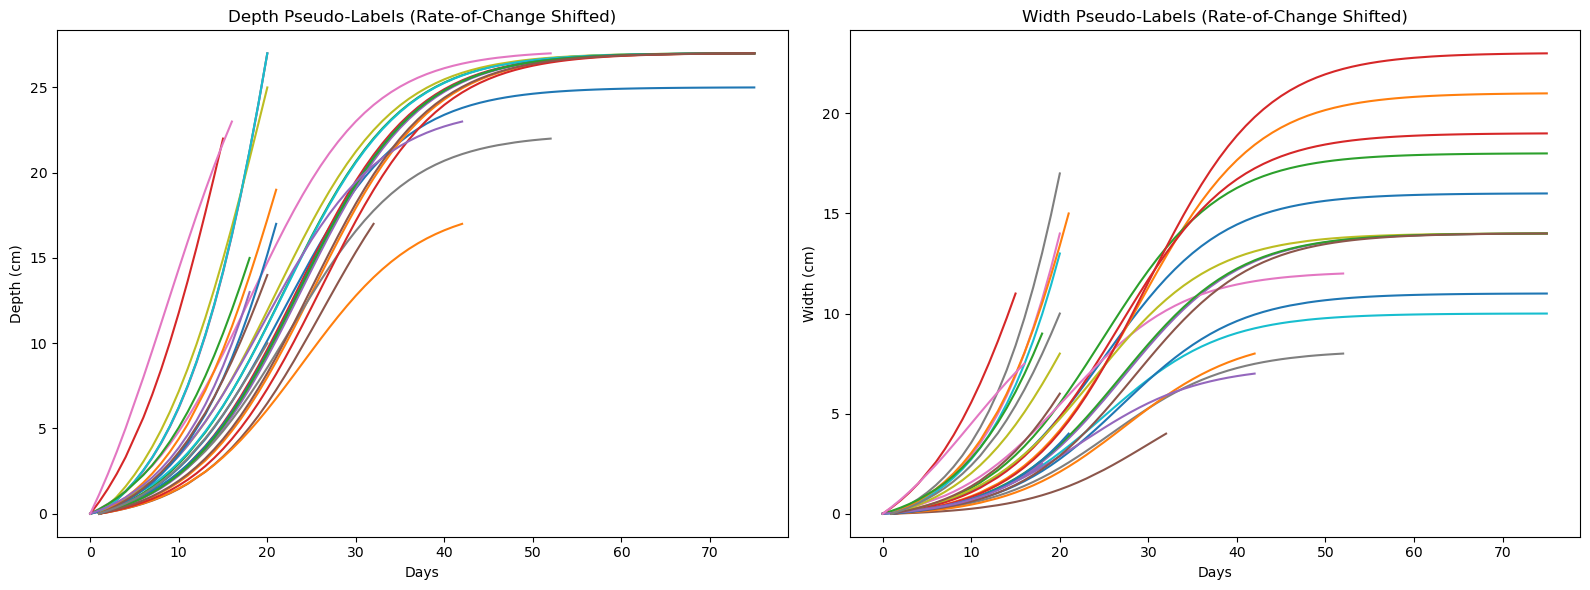

In [13]:

sensor_target = 'shallow_center'
plant_names = list(plants_feat.keys())

raw_rates = {}
for name in plant_names:
    raw_rates[name] = calculate_sensor_rate(
        plants_feat[name], 
        sensor_col=sensor_target, 
        reference_days=30.0, 
        method='max_gradient'
    )
rate_values = np.array(list(raw_rates.values()))
abs_rates = np.abs(rate_values) 
max_rate = np.max(abs_rates) if np.max(abs_rates) != 0 else 1.0
mean_rate = np.mean(abs_rates)
std_rate = np.std(abs_rates) if np.std(abs_rates) != 0 else 1.0

normalized_rate_shifts = {
    name: (2 * (abs_rates[i] - np.min(abs_rates)) / (np.max(abs_rates) - np.min(abs_rates) + 1e-8)) - 1.0
    for i, name in enumerate(plant_names)
}

pseudo_labels = {}
plot_names = ['plant1', 'plant1_v2', 'plant2_V4', 'plant1_V5']

plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
for name in plant_names:
    if name in final_depths:
        days = plants_feat[name].index.values if 'day' not in plants_feat[name] else plants_feat[name]['day'].values
        if len(days) == 0:
            days = np.arange(len(plants_feat[name])) 
        rate_shift = normalized_rate_shifts[name]
        depth_curve = generate_pseudo_labels(
            days, 
            final_depths[name], 
            rate_shift_score=rate_shift, 
            reference_days=35
        )
        pseudo_labels[name] = {'days': days, 'depth_target': depth_curve}
        plt.plot(days, depth_curve, alpha=1.0, label=f"{name} (shift={rate_shift:.2f})")
plt.title("Depth Pseudo-Labels (Rate-of-Change Shifted)")
plt.xlabel("Days")
plt.ylabel("Depth (cm)")

plt.subplot(1, 2, 2)
for name in plant_names:
    if name in final_widths:
        days = pseudo_labels[name]['days'] 
        rate_shift = normalized_rate_shifts[name]
        width_curve = generate_pseudo_labels(
            days, 
            final_widths[name], 
            rate_shift_score=rate_shift, 
            reference_days=40.0)
        pseudo_labels[name]['width_target'] = width_curve
        plt.plot(days, width_curve, alpha=1.0, label=f"{name}")

plt.title("Width Pseudo-Labels (Rate-of-Change Shifted)")
plt.xlabel("Days")
plt.ylabel("Width (cm)")

plt.tight_layout()
plt.show()

--- Starting Single Shape / Cascaded SVR LOPO-CV ---


I0000 00:00:1793111705.351862  412550 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1122 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070, pci bus id: 0000:01:00.0, compute capability: 8.6
I0000 00:00:1793111707.151084  412738 cuda_dnn.cc:529] Loaded cuDNN version 91700



================ DECOUPLED TWO-STAGE PERFORMANCE ================
ROOT DEPTH METRICS:
  Mean Absolute Error (MAE): 3.056 cm
  Root Mean Squared Error (RMSE): 3.937 cm
  R-squared (R²): 0.850
---------------------------------------------
ROOT WIDTH METRICS:
  Mean Absolute Error (MAE): 2.318 cm
  Root Mean Squared Error (RMSE): 3.031 cm
  R-squared (R²): 0.782




In [14]:
window_size = 12
sensor_cols = ['shallow_left', 'shallow_center', 'shallow_right', 'deep_left', 'deep_center', 'deep_right']


def create_windows(features, window_size):
    """Pads and slices 2D features into 3D timesteps for the GRU."""
    padded = np.pad(features, ((window_size - 1, 0), (0, 0)), mode='constant', constant_values=0)
    return np.array([padded[i : i + window_size, :] for i in range(len(features))])

def build_shape_model(input_shape):
    model = Sequential([
        Bidirectional(GRU(48, input_shape=input_shape, activation='tanh', return_sequences=False)),
        Dropout(0.2), 
        Dense(24, activation='relu'),
        Dropout(0.2), 
        Dense(12, activation='relu'), 
        Dense(2, activation='sigmoid')  
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.003), loss='mse')
    return model

plant_data = {}
plant_names = [name for name in plant_names if name in pseudo_labels and name in plants_feat]

for name in plant_names:
    df = plants_feat[name]
    n_days = len(df)
    
    calibrated_sensors = df[sensor_cols].values - df[sensor_cols].values[0, :]
    
    targets_depth = pseudo_labels[name]['depth_target']
    targets_width = pseudo_labels[name]['width_target']
    
    max_depth = np.max(targets_depth) if np.max(targets_depth) > 0 else 1.0
    max_width = np.max(targets_width) if np.max(targets_width) > 0 else 1.0
    
    shape_depth = targets_depth / max_depth  
    shape_width = targets_width / max_width  
    
    combined_targets = np.column_stack((targets_depth, targets_width)) 
    shape_targets = np.column_stack((shape_depth, shape_width))        
    final_targets = np.column_stack((np.full(n_days, max_depth), np.full(n_days, max_width))) 
    
    plant_data[name] = {
        'raw_sensors': calibrated_sensors, 
        'y': combined_targets, 
        'y_shape': shape_targets, 
        'y_final': final_targets
    }

all_true_targets = []
all_pred_filtered = []
out_of_sample_curves = {}

print("--- Starting Single Shape / Cascaded SVR LOPO-CV ---")
for test_plant in plant_names:
    X_train_list, y_shape_list, y_final_list, weight_list = [], [], [], []
    
    for train_plant in plant_names:
        if train_plant == test_plant:
            continue
            
        raw_s = plant_data[train_plant]['raw_sensors']
        y_s = plant_data[train_plant]['y_shape']
        y_f = plant_data[train_plant]['y_final']
        n_days = len(raw_s)

        base_weight = 10.0 if n_days < 30 else 1.0
        plant_weights = base_weight * np.geomspace(1.0, 100.0, n_days) 
        
        base_feat = generate_augmented_features(raw_s, scale=1.0)
        X_train_list.append(create_windows(base_feat, window_size))
        y_shape_list.append(y_s); y_final_list.append(y_f); weight_list.append(plant_weights)
        
        if n_days < 30:
            for s in [0.80, 0.90, 1.10, 1.20]:
                aug_feat = generate_augmented_features(raw_s, scale=s)
                X_train_list.append(create_windows(aug_feat, window_size))
                y_shape_list.append(y_s); y_final_list.append(y_f); weight_list.append(plant_weights)
                
            aug_feat_noise = generate_augmented_features(raw_s, noise_std=0.02)
            X_train_list.append(create_windows(aug_feat_noise, window_size))
            y_shape_list.append(y_s); y_final_list.append(y_f); weight_list.append(plant_weights)

            aug_feat_swap = generate_augmented_features(raw_s, swap_lr=True)
            X_train_list.append(create_windows(aug_feat_swap, window_size))
            y_shape_list.append(y_s); y_final_list.append(y_f); weight_list.append(plant_weights)
            
        else:
            for s in [0.85, 1.15]:
                aug_feat = generate_augmented_features(raw_s, scale=s)
                X_train_list.append(create_windows(aug_feat, window_size))
                y_shape_list.append(y_s); y_final_list.append(y_f); weight_list.append(plant_weights)
            
    X_train_raw = np.concatenate(X_train_list, axis=0)
    y_train_shape = np.concatenate(y_shape_list, axis=0)
    y_train_final = np.concatenate(y_final_list, axis=0)
    weights_train = np.concatenate(weight_list, axis=0)

    weights_train = weights_train / np.mean(weights_train)

    X_test_base = generate_augmented_features(plant_data[test_plant]['raw_sensors'], scale=1.0)
    X_test_raw = create_windows(X_test_base, window_size)
    y_test_actual = plant_data[test_plant]['y'] 
    
    num_samples_train, timesteps, num_features = X_train_raw.shape
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_raw.reshape(-1, num_features)).reshape(num_samples_train, timesteps, num_features)
    X_test_scaled = scaler.transform(X_test_raw.reshape(-1, num_features)).reshape(X_test_raw.shape[0], timesteps, num_features)
  
    shape_model = build_shape_model((timesteps, num_features))
    shape_model.fit(X_train_scaled, y_train_shape, sample_weight=weights_train, epochs=65, batch_size=64, verbose=0) 

    X_train_rf = X_train_scaled[:, -3:, :].reshape(num_samples_train, -1)
    X_test_rf = X_test_scaled[:, -3:, :].reshape(X_test_scaled.shape[0], -1)
  
    pca = PCA(n_components=0.98, random_state=42)
    X_train_rf_pca = pca.fit_transform(X_train_rf)
    X_test_rf_pca = pca.transform(X_test_rf)
    
    depth_scale_model = SVR(kernel='rbf', C=1.0, epsilon=0.1)
    depth_scale_model.fit(X_train_rf_pca, y_train_final[:, 0], sample_weight=weights_train)

    pred_scale_depth_train = depth_scale_model.predict(X_train_rf_pca)
    pred_scale_depth_test = depth_scale_model.predict(X_test_rf_pca)

    X_train_width_cascade = np.column_stack((X_train_rf_pca, pred_scale_depth_train))
    X_test_width_cascade = np.column_stack((X_test_rf_pca, pred_scale_depth_test))

    width_scale_model = SVR(kernel='rbf', C=0.5, epsilon=0.2)
    width_scale_model.fit(X_train_width_cascade, y_train_final[:, 1], sample_weight=weights_train)
 
    pred_shape = shape_model.predict(X_test_scaled, verbose=0) 
    pred_scale_width_test = width_scale_model.predict(X_test_width_cascade)

    pred_scale = np.column_stack((pred_scale_depth_test, pred_scale_width_test))
    raw_predictions = pred_shape * pred_scale 

    filtered_predictions = np.zeros_like(raw_predictions)
    n_days = len(raw_predictions)
    days_array = np.arange(n_days)
    window_length = min(11, n_days | 1)
    iso = IsotonicRegression(increasing=True, out_of_bounds='clip')
    iso_depth = iso.fit_transform(days_array, raw_predictions[:, 0])
    iso_width = iso.fit_transform(days_array, raw_predictions[:, 1])

    if window_length > 3:
        actual_window = min(window_length, len(iso_depth))
        if actual_window % 2 == 0:
            actual_window -= 1
            
        if actual_window > 2:
            smooth_depth = savgol_filter(iso_depth, actual_window, polyorder=2)
            smooth_width = savgol_filter(iso_width, actual_window, polyorder=2)
        else:
            smooth_depth = iso_depth
            smooth_width = iso_width
        filtered_predictions[:, 0] = np.maximum.accumulate(np.maximum(smooth_depth, 0))
        filtered_predictions[:, 1] = np.maximum.accumulate(np.maximum(smooth_width, 0))
    else:
        filtered_predictions[:, 0] = iso_depth
        filtered_predictions[:, 1] = iso_width 
    out_of_sample_curves[test_plant] = filtered_predictions
    all_true_targets.append(y_test_actual)
    all_pred_filtered.append(filtered_predictions)

# --- 4. Final Evaluation ---
all_true = np.concatenate(all_true_targets, axis=0)
all_pred = np.concatenate(all_pred_filtered, axis=0)

depth_mae = mean_absolute_error(all_true[:, 0], all_pred[:, 0])
depth_rmse = np.sqrt(mean_squared_error(all_true[:, 0], all_pred[:, 0]))
depth_r2 = r2_score(all_true[:, 0], all_pred[:, 0])

width_mae = mean_absolute_error(all_true[:, 1], all_pred[:, 1])
width_rmse = np.sqrt(mean_squared_error(all_true[:, 1], all_pred[:, 1]))
width_r2 = r2_score(all_true[:, 1], all_pred[:, 1])

print("\n================ DECOUPLED TWO-STAGE PERFORMANCE ================")
print(f"ROOT DEPTH METRICS:")
print(f"  Mean Absolute Error (MAE): {depth_mae:.3f} cm")
print(f"  Root Mean Squared Error (RMSE): {depth_rmse:.3f} cm")
print(f"  R-squared (R²): {depth_r2:.3f}")
print("-" * 45)
print(f"ROOT WIDTH METRICS:")
print(f"  Mean Absolute Error (MAE): {width_mae:.3f} cm")
print(f"  Root Mean Squared Error (RMSE): {width_rmse:.3f} cm")
print(f"  R-squared (R²): {width_r2:.3f}")
print("=================================================================")

# Trigger the plotting function 
plot_all_lopocv_results(plant_names, plant_data, out_of_sample_curves)



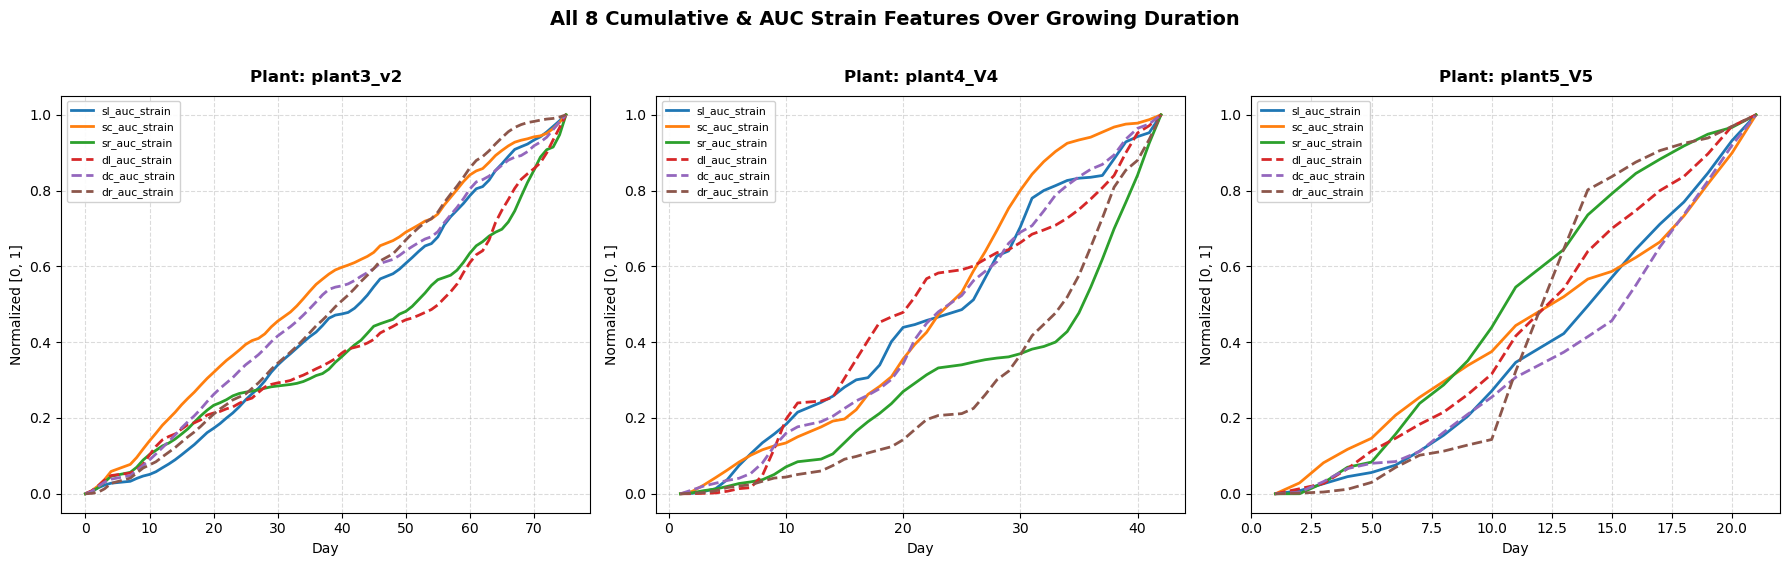

In [15]:
RANDOM_SEED = None            
NORMALIZE_FEATURES = True     
SHOW_TARGET_OVERLAY = False   

sensors = ['sl', 'sc', 'sr', 'dl', 'dc', 'dr']
feature_names = (
    [f'{s}_raw' for s in sensors] +
    [f'{s}_roll3' for s in sensors] +
    [f'{s}_roll7' for s in sensors] +
    [f'{s}_std5' for s in sensors] +
    ['spatial_ratio', 'running_cumulative_work', 'daily_work', 'side_ratio'] +
    [f'{s}_delta' for s in sensors] +
    [f'{s}_volatility' for s in sensors] +
    ['corr_center', 'corr_left', 'corr_right', 'corr_shallow_lr', 'corr_deep_lr'] +
    [f'{s}_max_velocity' for s in sensors] +
    [f'{s}_auc_strain' for s in sensors] +
    ['asym_variance', 'outer_inner_ratio', 'cum_spatial_divergence']
)

candidate_8_auc = [
    'sl_auc_strain',
    'sc_auc_strain',
    'sr_auc_strain',
    'dl_auc_strain',
    'dc_auc_strain',
    'dr_auc_strain',]

if 'feature_names' in globals():
    auc_matches = [f for f in feature_names if 'auc_strain' in f]
    if len(auc_matches) == 8:
        selected_feature_names = auc_matches
    else:
        selected_feature_names = [f for f in candidate_8_auc if f in feature_names]
    selected_feature_indices = [feature_names.index(f) for f in selected_feature_names]
else:
    selected_feature_names = candidate_8_auc
    selected_feature_indices = list(range(len(candidate_8_auc)))

if RANDOM_SEED is not None:
    np.random.seed(RANDOM_SEED)
selected_plants = ['plant3_v2', 'plant4_V4', 'plant5_V5']
selected_plants = [p for p in selected_plants if p in plant_data]
if len(selected_plants) < 3 and 'plant_names' in globals():
    remaining = [p for p in plant_names if p not in selected_plants and p in plant_data]
    selected_plants += list(np.random.choice(remaining, size=3 - len(selected_plants), replace=False))

fig, axes = plt.subplots(1, len(selected_plants), figsize=(18, 5.5), sharey=False)
if len(selected_plants) == 1:
    axes = [axes]

palette = ['#1f77b4', '#ff7f0e', '#2ca02c','#d62728', '#9467bd', '#8c564b','#e377c2', '#17becf']
line_styles = ['-', '-', '-', '--', '--', '--', '-.', ':']

for i, p in enumerate(selected_plants):
    ax = axes[i]
    raw_s = plant_data[p]['raw_sensors']
    feat_matrix = generate_augmented_features(raw_s, scale=1.0)
    if 'plants_feat' in globals() and p in plants_feat and 'day' in plants_feat[p]:
        days = plants_feat[p]['day'].values
        x_label = 'Day'
    else:
        days = np.arange(len(feat_matrix))
        x_label = 'Days Elapsed'
    for f_i, (feat_idx, feat_name) in enumerate(zip(selected_feature_indices, selected_feature_names)):
        y_val = feat_matrix[:, feat_idx]
        if NORMALIZE_FEATURES:
            y_min, y_max = y_val.min(), y_val.max()
            y_val = (y_val - y_min) / (y_max - y_min + 1e-8)
        ax.plot(
            days, y_val,
            label=feat_name,
            color=palette[f_i % len(palette)],
            linestyle=line_styles[f_i % len(line_styles)],
            linewidth=2.0)
        
    ax.set_title(f"Plant: {p}", fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel(x_label, fontsize=10)
    ax.set_ylabel("Normalized [0, 1]" if NORMALIZE_FEATURES else "Feature Value", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.45)
    ax.legend(loc='upper left', fontsize=7.8, framealpha=0.9, ncol=1)
    if SHOW_TARGET_OVERLAY and 'y' in plant_data[p]:
        ax_twin = ax.twinx()
        y_act = plant_data[p]['y']
        ax_twin.plot(days, y_act[:, 0], 'k--', alpha=0.6, linewidth=1.8, label='Target Depth (cm)')
        ax_twin.plot(days, y_act[:, 1], 'k:', alpha=0.6, linewidth=1.8, label='Target Width (cm)')
        ax_twin.set_ylabel("Target (cm)", fontsize=9, color='black')
        ax_twin.legend(loc='lower right', fontsize=7.5, framealpha=0.8)

plt.suptitle("All 8 Cumulative & AUC Strain Features Over Growing Duration", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()